# Solving Inverse Problem using sLORETA

## Imports

In [1]:
#%matplotlib qt

import mindmap as mm
import mne
import numpy as np
from pathlib import Path

config = mm.io.read_config("../configurations/spike.yml")
mm_dir = Path(config["MM_DIR"])
fs_dir = Path(config["FS_DIR"])

## Data

In [2]:
sub     = "sub-pat09"

# files
forward = mm_dir/sub/"fwd"/f"{sub}_surf-fwd.fif"
eeg     = mm_dir/sub/"eeg"/f"{sub}_ave.fif"

# parameters
lam           = 0.01

# plotting parameters
plot_kwargs = dict(
    subject = sub, 
    hemi = "both", 
    surface = "white",
    smoothing_steps = 10,
    subjects_dir = fs_dir,
)

# load
eeg       = mne.read_evokeds(eeg)[0]
forward   = mne.read_forward_solution(forward)
noise_cov = mne.make_ad_hoc_cov(eeg.info, std={"eeg":1})

Reading /home/admin/work/data/eeg_epi_spikeerp_data_1.0.0/derivatives/mindmap/sub-pat09/eeg/sub-pat09_ave.fif ...
    Found the data of interest:
        t =       0.00 ...     252.00 ms (No comment)
        0 CTF compensation matrices available
        nave = 1 - aspect type = 100
No projector specified for this dataset. Please consider the method self.add_proj.
Loaded Evoked data is baseline-corrected (baseline: [0, 0.2] s)
Reading forward solution from /home/admin/work/data/eeg_epi_spikeerp_data_1.0.0/derivatives/mindmap/sub-pat09/fwd/sub-pat09_surf-fwd.fif...
    Reading a source space...
    Computing patch statistics...
    Patch information added...
    Distance information added...
    [done]
    Reading a source space...
    Computing patch statistics...
    Patch information added...
    Distance information added...
    [done]
    2 source spaces read
    Desired named matrix (kind = 3523) not available
    Read EEG forward solution (5200 sources, 204 channels, free orientat

## Select time points to reconstruct

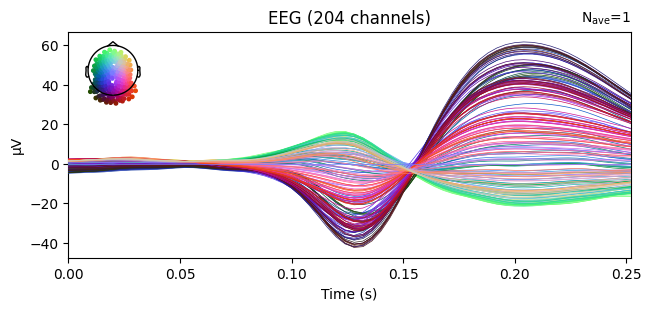

In [3]:
_ = eeg.plot()

Number of time points: (204, 26)


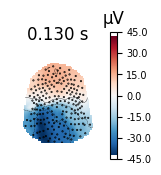

In [4]:
tmin  = 0.08
tmax  = 0.18
tviz  = 0.13
sfreq = eeg.info["sfreq"]

b = eeg.crop(tmin, tmax)

print(f"Number of time points: {b.data.shape}")
_ = eeg.plot_topomap([tviz], outlines=None, extrapolate="local")

## sLORETA

In [5]:
b.set_eeg_reference(projection=True)

inverse = mne.minimum_norm.make_inverse_operator(
    b.info,
    forward,
    noise_cov,
    loose=0,
    depth=0.8,
)

stc = mne.minimum_norm.apply_inverse(
    b, 
    inverse, 
    lambda2=lam,
    method="sLORETA",
)

EEG channel type selected for re-referencing
Adding average EEG reference projection.
1 projection items deactivated
Average reference projection was added, but has not been applied yet. Use the apply_proj method to apply it.
Computing inverse operator with 204 channels.
    204 out of 204 channels remain after picking
Selected 204 channels
Creating the depth weighting matrix...
    204 EEG channels
    limit = 5201/5200 = 2.521457
    scale = 480931 exp = 0.8
    Picked elements from a free-orientation depth-weighting prior into the fixed-orientation one
    Average patch normals will be employed in the rotation to the local surface coordinates....
    Converting to surface-based source orientations...
    [done]
Whitening the forward solution.
    Created an SSP operator (subspace dimension = 1)
Computing rank from covariance with rank=None
    Using tolerance 0.00045 (2.2e-16 eps * 204 dim * 1e+10  max singular value)
    Estimated rank (eeg): 203
    EEG: rank 203 computed from 204

## Visualize

In [6]:
sol = stc.data
mm.viz.plot_brain_time_series(forward["src"], np.abs(sol), sfreq, cmap="reds")

Widget(value='<iframe src="http://localhost:34671/index.html?ui=P_0x7f6adaeb1f10_0&reconnect=auto" class="pyvi…

In [7]:
stc.plot(clim = {"kind":"value", "lims":[0, stc.data.max()/2, stc.data.max()]}, **plot_kwargs)

Using pyvistaqt 3d backend.

For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`
For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`
For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`
For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`


In [7]:
save = "mne"
#save = "bv"

fname  = f"{sub}_sloreta-{lam}"
folder = mm_dir/sub/"stc"

if folder.exists() == False:
    folder.mkdir(parents=True)

print(f"Saving estimation for subject: {sub}")
if save == "mne":
    stc.save(folder/fname, overwrite=True)
if save == "bv":
    trans = mm.utils.compute_transformation(sub, fs_dir, "mri", "head", "m")
    mm.io.write_stc(
        fname  = fname,
        folder = folder,
        stc    = stc, 
        src    = forward["src"],
        trans  = trans, 
        overwrite = True, 
    )

Saving estimation for subject: sub-pat09
Writing STC to disk...
[done]
